In [ ]:
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import rasterio
import glob
import pandas as pd
from sklearn.decomposition import PCA
from pathlib import Path
from sklearn.preprocessing import StandardScaler, normalize
import random
import geopandas as gpd
from shapely.geometry import box
from shapely.ops import unary_union
import re
import shapely
import shapely

In [282]:


BOUNDS_CRS = 'EPSG:32633'   # CRS the shapefiles are stored in
WORK_CRS = 'ESRI:102025'    # equal-area, so overlap_area is meaningful
OUT_DIR = Path('/Users/wm722/Documents/SCDs/results/Inference')


def clean_embeddings(gdf):
    embed_cols = [f'emb_{i}' for i in range(36)]
    gdf['embeddings'] = gdf[embed_cols].values.tolist()
    return gdf.drop(columns=embed_cols + ['embedding'])


def parse_bounds(line):
    line = line.replace('Bounds of DEM: BoundingBox(', '').replace(')', '')
    return tuple(float(part.split('=')[1]) for part in line.split(', '))


def short(p):
    p = Path(p)
    return f'{p.parent.parent.name}/{p.parent.name}'


def zone_crs(path):
    zone = int(re.search(r'Zone(\d+)', str(path), re.I).group(1))
    return f'EPSG:326{zone:02d}'


def to_common_crs(gdf_dict, crs):
    out = {}
    for k, v in gdf_dict.items():
        poly = shapely.segmentize(box(*v['covered_bounds']), 1000)
        poly = gpd.GeoSeries([poly], crs=zone_crs(k)).to_crs(crs).iloc[0]
        out[k] = {'gdf': v['gdf'].to_crs(crs), 'covered_poly': poly}
    return out


def plot_xy_data(gdf, feature_col, ax):
    data = gdf[feature_col]

    # scatter plot of centroids colored by feature value
    gdf['centroid'] = gdf['geometry'].centroid
    ax.scatter(gdf['centroid'].x, gdf['centroid'].y, c=data, cmap='viridis', s=5)
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')
    ax.set_aspect('equal')

    # show colorbar
    cbar = plt.colorbar(ax.collections[0], ax=ax)
    cbar.set_label(feature_col)


def remove_overlap(gdf_dict, seed=None):
    rng = random.Random(seed)
    order = list(gdf_dict)
    rng.shuffle(order)

    claimed = None
    footprints = {}
    kept, rows = [], []

    for k in order:
        gdf = gdf_dict[k]['gdf']
        footprint = gdf_dict[k]['covered_poly']
        n_in = len(gdf)
        n_trimmed = 0

        overlaps_with = [p for p, f in footprints.items() if footprint.intersects(f)]
        overlap_area = 0.0

        if overlaps_with:
            overlap_area = footprint.intersection(
                unary_union([footprints[p] for p in overlaps_with])).area

            if (gdf.geom_type == 'Point').all():
                gdf = gdf[~gdf.geometry.intersects(claimed)]
            else:
                gdf = gdf.copy()
                n_trimmed = int(gdf.geometry.intersects(claimed).sum())
                gdf['geometry'] = gdf.geometry.make_valid().difference(claimed)
                gdf = gdf[~gdf.geometry.is_empty]

        rows.append({
            'tile': short(k),
            'overlaps_with': ', '.join(short(p) for p in overlaps_with) or '-',
            'overlap_area': overlap_area,
            'rows_in': n_in,
            'rows_out': len(gdf),
            'rows_removed': n_in - len(gdf),
            'rows_trimmed': n_trimmed,
        })

        kept.append(gdf.assign(tile=short(k)))
        footprints[k] = footprint
        claimed = footprint if claimed is None else unary_union([claimed, footprint])

    report = pd.DataFrame(rows)
    with pd.option_context('display.width', 250, 'display.max_columns', None,
                           'display.max_colwidth', 80):
        print(report.to_string(index=False))
    print(f"\ntiles: {len(report)}  rows in: {report.rows_in.sum()}  "
          f"rows out: {report.rows_out.sum()}  removed: {report.rows_removed.sum()}  "
          f"tiles with overlap: {(report.overlaps_with != '-').sum()}")

    return kept, report

covered = []
paths = glob.glob(str(OUT_DIR / '*/*/predictions.shp'))
gdf_dict = {}
for p in map(Path, paths):
    bounds_txt = p.parent / 'covered_bounds.txt'
    if not bounds_txt.exists():
        print(f'no bounds file for {p}, skipping')
        continue

    with open(bounds_txt) as f:
        bounds = parse_bounds(f.readlines()[1].strip())

    g = gpd.read_file(p)
    if g.crs is None:
        g = g.set_crs(BOUNDS_CRS)

    gdf_dict[p] = {'covered_bounds': bounds, 'gdf': g}
    covered.append(box(*bounds))
tiles = to_common_crs(gdf_dict, WORK_CRS)

for k, v in tiles.items():
    inside = v['gdf'].geometry.within(v['covered_poly'].buffer(1000)).mean()
    print(round(inside, 3), short(k))

gdfs, report = remove_overlap(tiles, seed=42)

gdf = pd.concat(gdfs, ignore_index=True).to_crs('EPSG:4326')
gdf.to_file(OUT_DIR / 'merged_predictions.shp', driver='ESRI Shapefile')

1.0 Zone45/Lat_52_56
1.0 Zone42/Lat_52_56
1.0 Zone43/Lat_52_56
1.0 Zone44/Lat_52_56
1.0 Zone36/Lats_52_56
1.0 Zone36/Lats_47_52
1.0 Zone38/Lats_52_56
1.0 Zone38/Lats_47_52
1.0 Zone39/Lats_47_52_Zone39_Inference_2
1.0 Zone39/lats_52_56
1.0 Zone37/Lats_47_52
1.0 Zone37/Zone37_Lats_52_56
1.0 Zone41/Lat_52_56
1.0 Zone41/Lats_47_52
1.0 Zone40/Lats_47_52
                                tile                                                                                        overlaps_with  overlap_area  rows_in  rows_out  rows_removed  rows_trimmed
Zone39/Lats_47_52_Zone39_Inference_2                                                                                                    -  0.000000e+00     6069      6069             0             0
                   Zone41/Lats_47_52                                                                                                    -  0.000000e+00     5131      5131             0             0
                   Zone38/Lats_47_52                

In [ ]:
import glob
import re
import shutil
from itertools import combinations
from pathlib import Path

import geopandas as gpd
import shapely
from shapely.geometry import box
from shapely.ops import unary_union

SRC = Path('/Users/wm722/Documents/SCDs/results/Inference')
OUT = Path('/Users/wm722/Documents/SCDs/results/InferenceCleaned')
QGIS = Path('~/Documents/SCDs/results/QGIS').expanduser()
WORK_CRS = 'ESRI:102025'
BOUNDS_CRS = 'EPSG:32633'


def zone_crs(path):
    zone = int(re.search(r'Zone(\d+)', str(path), re.I).group(1))
    return f'EPSG:326{zone:02d}'


def parse_bounds(line):
    line = line.replace('Bounds of DEM: BoundingBox(', '').replace(')', '')
    return tuple(float(p.split('=')[1]) for p in line.split(', '))


def footprint(run_dir):
    line = (run_dir / 'covered_bounds.txt').read_text().splitlines()[1].strip()
    poly = shapely.segmentize(box(*parse_bounds(line)), 1000)
    return gpd.GeoSeries([poly], crs=zone_crs(run_dir)).to_crs(WORK_CRS).iloc[0]


runs = [Path(p).parent for p in sorted(glob.glob(str(SRC / '*/*/predictions.shp')))]
runs = [d for d in runs if (d / 'covered_bounds.txt').exists()]

cov = {d: footprint(d) for d in runs}
remove = {d: [] for d in runs}
dup_geoms, dup_names = [], []

for a, b in combinations(runs, 2):
    inter = cov[a].intersection(cov[b])
    if inter.area < 1:
        continue
    cov[b] = cov[b].difference(inter)
    remove[b].append(inter)
    dup_geoms.append(inter)
    dup_names.append(f'{a.parent.name}/{a.name} x {b.parent.name}/{b.name}')
    print(f'{a.parent.name}/{a.name} x {b.parent.name}/{b.name}: '
          f'trimmed {inter.area / 1e6:,.0f} km2 from second')

shutil.copytree(SRC, OUT, dirs_exist_ok=True)

for d in runs:
    if not remove[d]:
        continue
    dest = OUT / d.relative_to(SRC)
    mask = unary_union(remove[d])

    for shp in dest.glob('*.shp'):
        g = gpd.read_file(shp)
        if g.crs is None:
            g = g.set_crs(BOUNDS_CRS)
        m = gpd.GeoSeries([mask], crs=WORK_CRS).to_crs(g.crs).iloc[0]
        n_in = len(g)
        g['geometry'] = g.geometry.make_valid().difference(m)
        g = g[~g.geometry.is_empty]
        g.to_file(shp)
        print(f'{dest.parent.name}/{dest.name}/{shp.name}: {n_in} -> {len(g)} features')

QGIS.mkdir(parents=True, exist_ok=True)

covered = gpd.GeoDataFrame(
    {'run': [f'{d.parent.name}/{d.name}' for d in runs]},
    geometry=[cov[d] for d in runs], crs=WORK_CRS)
covered.to_crs('EPSG:4326').to_file(QGIS / 'covered_tiles.gpkg', driver='GPKG')

dups = gpd.GeoDataFrame({'pair': dup_names}, geometry=dup_geoms, crs=WORK_CRS)
dups.to_crs('EPSG:4326').to_file(QGIS / 'duplicate_tiles.gpkg', driver='GPKG')

Zone36/Lats_47_52 x Zone36/Lats_52_56: trimmed 4,160 km2 from second
Zone36/Lats_47_52 x Zone37/Lats_47_52: trimmed 97,425 km2 from second
Zone36/Lats_47_52 x Zone37/Zone37_Lats_52_56: trimmed 1,063 km2 from second
Zone36/Lats_52_56 x Zone37/Lats_47_52: trimmed 195 km2 from second
Zone36/Lats_52_56 x Zone37/Zone37_Lats_52_56: trimmed 69,230 km2 from second
Zone37/Lats_47_52 x Zone37/Zone37_Lats_52_56: trimmed 3,097 km2 from second
Zone37/Lats_47_52 x Zone38/Lats_47_52: trimmed 97,425 km2 from second
Zone37/Lats_47_52 x Zone38/Lats_52_56: trimmed 1,063 km2 from second
Zone37/Zone37_Lats_52_56 x Zone38/Lats_47_52: trimmed 195 km2 from second
Zone37/Zone37_Lats_52_56 x Zone38/Lats_52_56: trimmed 69,230 km2 from second
Zone38/Lats_47_52 x Zone38/Lats_52_56: trimmed 3,097 km2 from second
Zone38/Lats_47_52 x Zone39/Lats_47_52_Zone39_Inference_2: trimmed 97,425 km2 from second
Zone38/Lats_47_52 x Zone39/lats_52_56: trimmed 1,063 km2 from second
Zone38/Lats_52_56 x Zone39/Lats_47_52_Zone39_Inf

In [268]:
gdf = clean_embeddings(gdf)

In [285]:
total_covered = unary_union(covered)

total_covered_gdf = gpd.GeoDataFrame(geometry=[total_covered], crs=BOUNDS_CRS)


/var/folders/v2/pgp80k4j40j5r2z4b2mmlr1w0000gp/T/ipykernel_85008/1201833795.py:40: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  gdf['centroid'] = gdf['geometry'].centroid


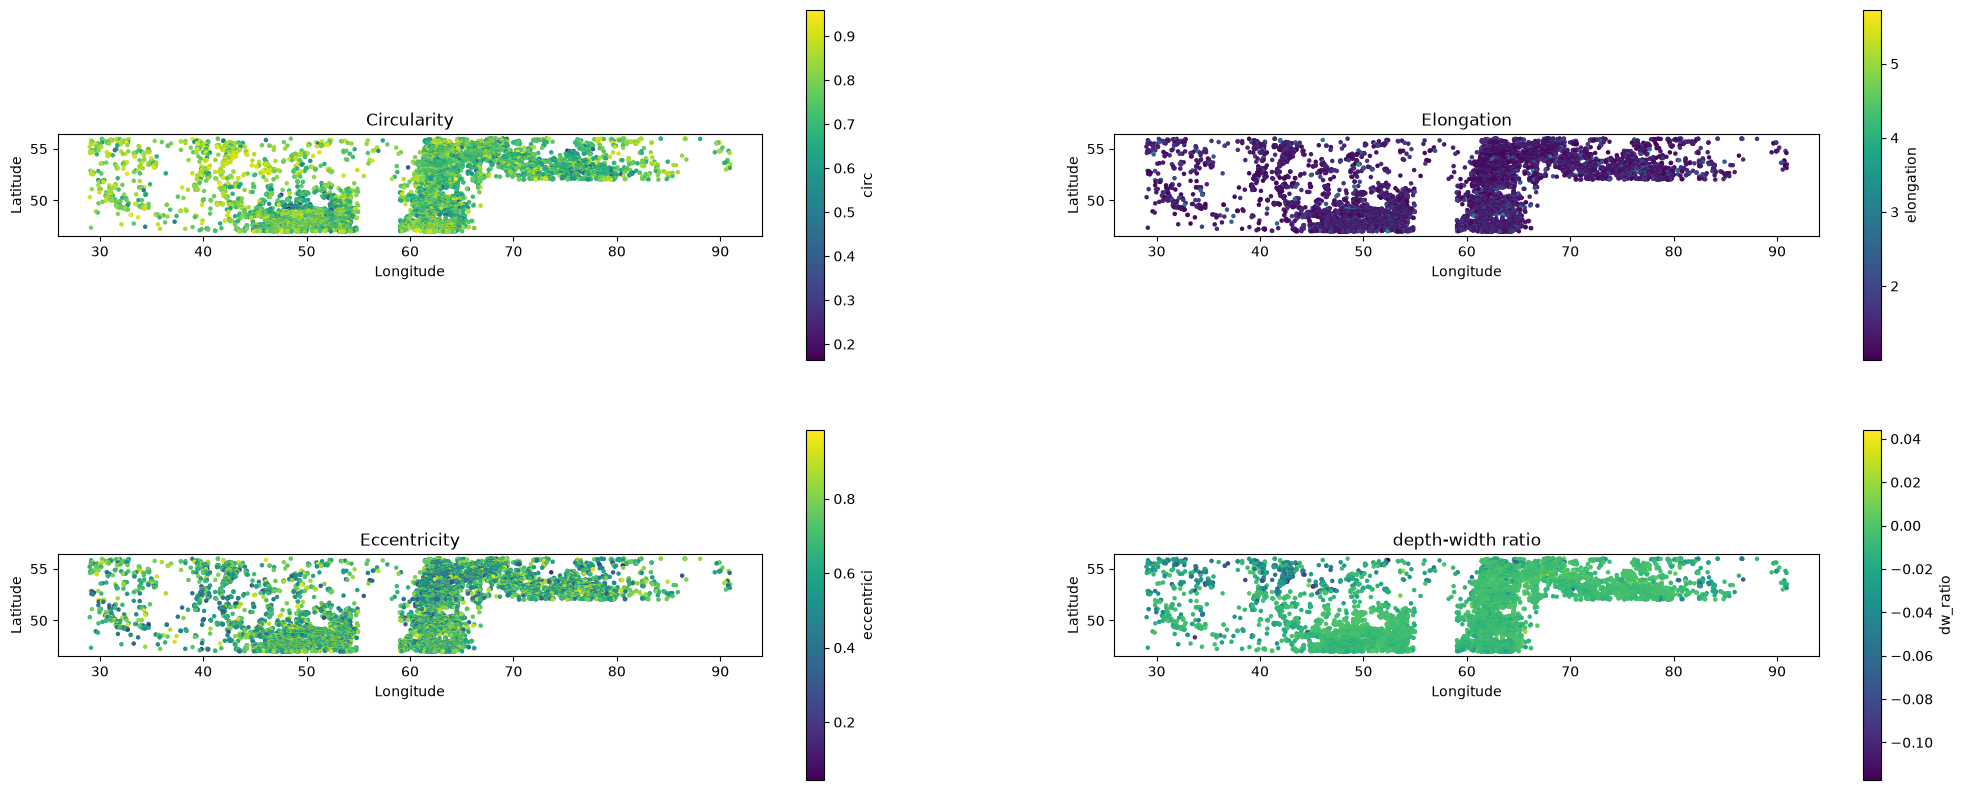

In [280]:
# multipanel figure in (x, y) space showing how circularity, elongation, etc, change spatially. Scatter plot (with centroid, hue by feature value)

fig, axes = plt.subplots(2, 2, figsize=(25, 10))

axes[0, 0].set_title('Circularity')
plot_xy_data(gdf, 'circ', axes[0, 0])
axes[0, 1].set_title('Elongation')
plot_xy_data(gdf, 'elongation', axes[0, 1])
axes[1, 0].set_title('Eccentricity')
plot_xy_data(gdf, 'eccentrici', axes[1, 0])
axes[1, 1].set_title('depth-width ratio')
plot_xy_data(gdf, 'dw_ratio', axes[1, 1])

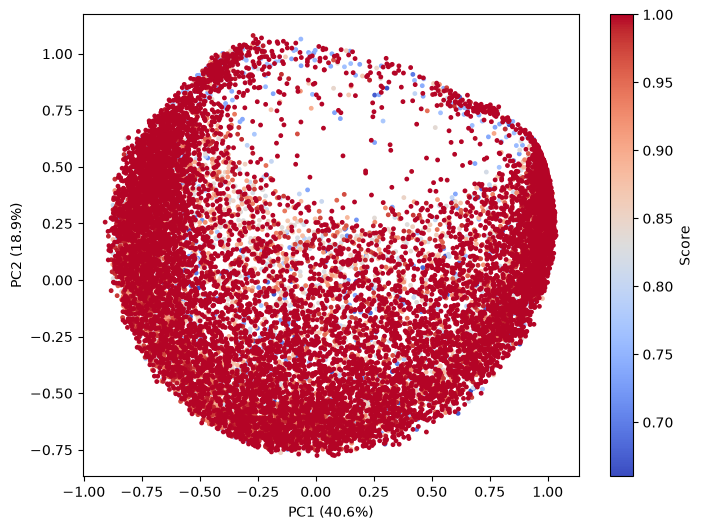

In [269]:
# PCA of embeddings to 2d. plot of pca1 vs pca2.

pca = PCA(n_components=2)
embeddings = np.array(gdf['embeddings'].tolist())

X = np.array(gdf['embeddings'].tolist())
X = normalize(StandardScaler().fit_transform(X))

pca_result = pca.fit_transform(X)

fig, ax = plt.subplots(figsize=(8, 6))
order = np.argsort(gdf['score'].values)
scatter = ax.scatter(pca_result[order, 0], pca_result[order, 1],
           c=gdf['score'].values[order], cmap='coolwarm',
           s=6)

plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})") 
plt.colorbar(scatter, ax=ax, label='Score')


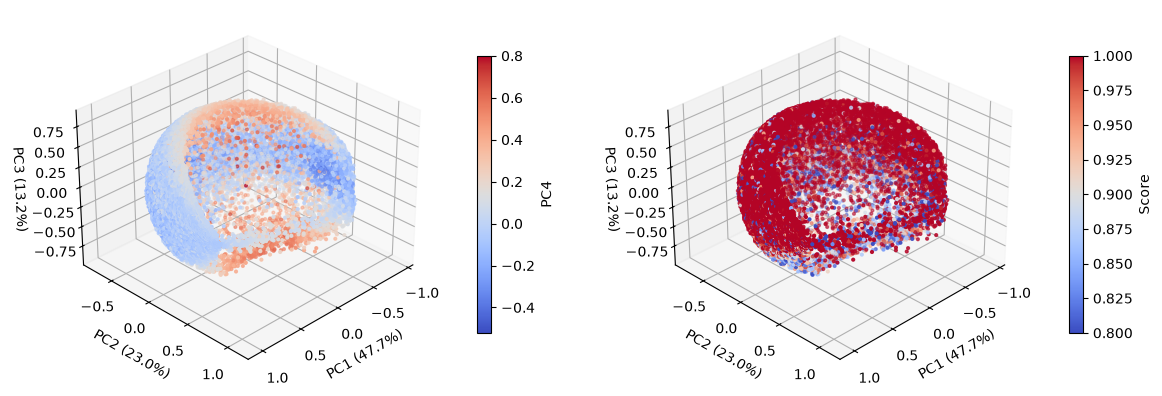

In [242]:
pca4 = PCA(n_components=4)
p = pca4.fit_transform(X)
ev = pca4.explained_variance_ratio_
score = gdf['score'].values
order = np.argsort(-score)  # low scores drawn last

fig = plt.figure(figsize=(14, 6))

def panel(pos, c, label, **kw):
    ax = fig.add_subplot(pos, projection='3d')
    sc = ax.scatter(p[order, 0], p[order, 1], p[order, 2], c=c[order],
                    cmap='coolwarm', s=4, **kw)
    ax.set_xlabel(f"PC1 ({ev[0]:.1%})")
    ax.set_ylabel(f"PC2 ({ev[1]:.1%})")
    ax.set_zlabel(f"PC3 ({ev[2]:.1%})")
    ax.view_init(elev=30, azim=45)
    fig.colorbar(sc, ax=ax, shrink=0.6, pad=0.1, label=label)

panel(121, p[:, 3], 'PC4')
panel(122, score, 'Score', vmin=0.8, vmax=1)


In [272]:
gdf_confident = gdf[gdf['score'] > 0.95]

/var/folders/v2/pgp80k4j40j5r2z4b2mmlr1w0000gp/T/ipykernel_85008/270476330.py:40: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  gdf['centroid'] = gdf['geometry'].centroid


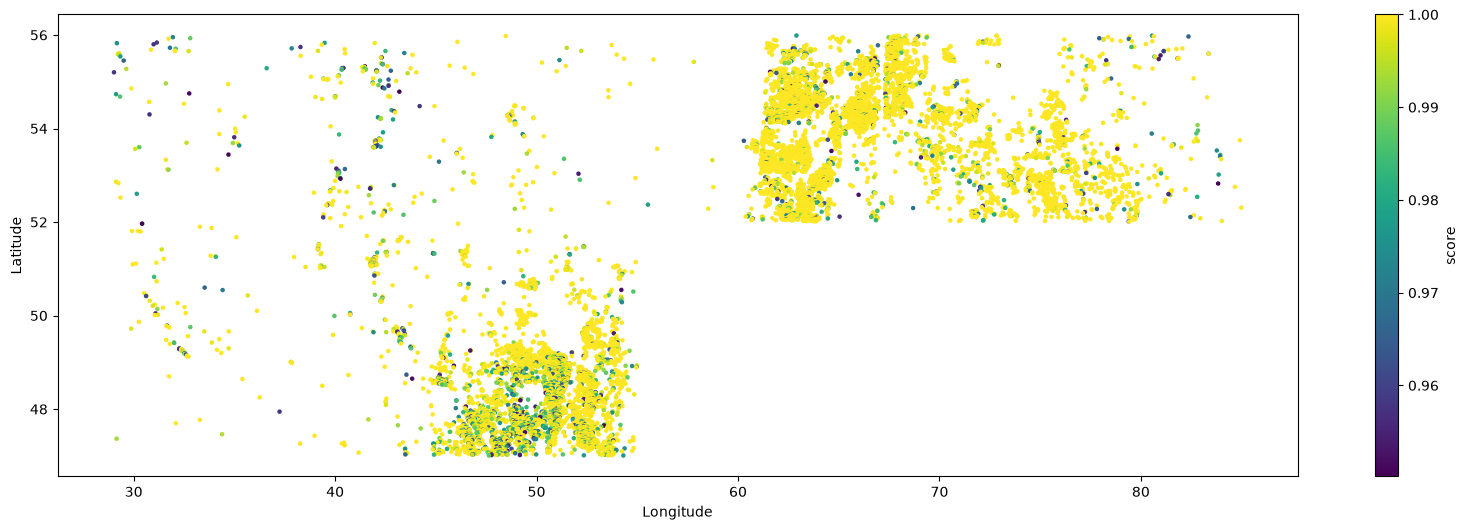

In [276]:
# xy space, hue by pca1
fig, ax = plt.subplots(figsize=(20, 6))
plot_xy_data(gdf_confident, 'score', ax)

/var/folders/v2/pgp80k4j40j5r2z4b2mmlr1w0000gp/T/ipykernel_85008/2009558905.py:51: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  gdf['centroid'] = gdf['geometry'].centroid


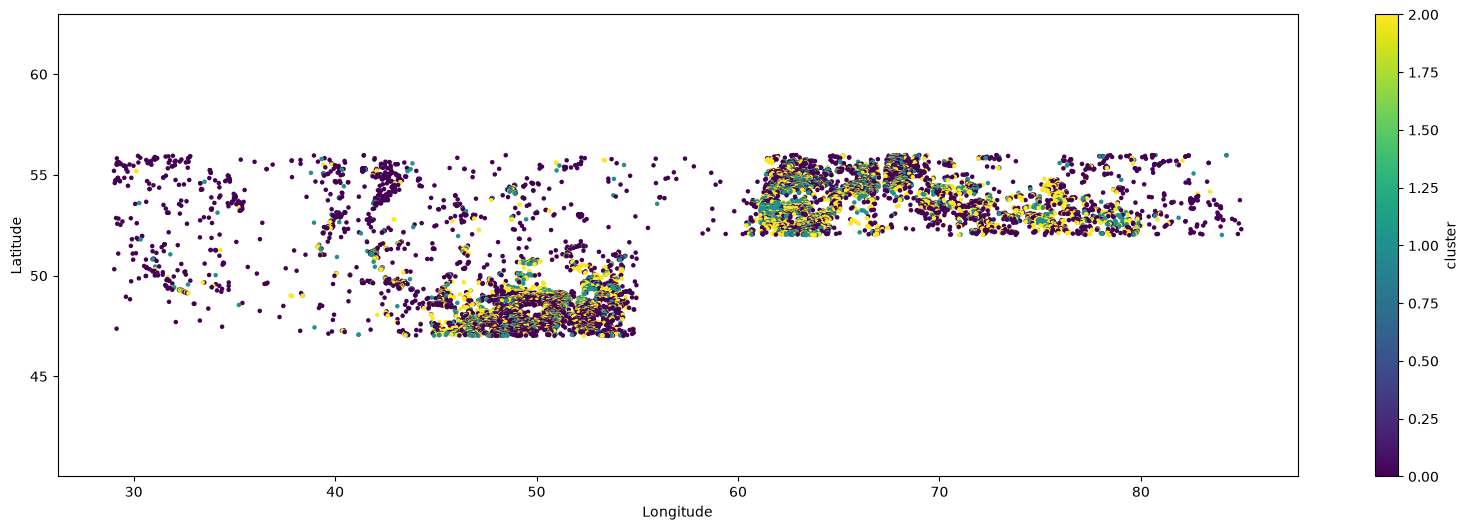

In [245]:
from sklearn.neighbors import kneighbors_graph
from sklearn.cluster import AgglomerativeClustering

fig, ax = plt.subplots(figsize=(20, 6))
conn = kneighbors_graph(X, n_neighbors=50, include_self=False)
gdf['cluster'] = AgglomerativeClustering(
    n_clusters=3, connectivity=conn, linkage='ward'
).fit_predict(X)

plot_xy_data(gdf, 'cluster', ax)


# Dataset Morphologies

In [ ]:
def normalise_veto_data(candidates, norm_stats):
    if candidates is None:
        return None

    dem = _handle_outliers(candidates)
    med = np.median(dem, axis=(1, 2), keepdims=True)
    return (dem - med) / norm_stats['Candidate_DEM']['iqr']


def _handle_outliers(a, lo=1, hi=99):
    l, h = np.nanpercentile(a, [lo, hi])
    return np.clip(a, l, h)


In [214]:

model = torch.load("/Users/wm722/Documents/SCDs/models/RussiaVetoer.pt", map_location=torch.device('cpu'))
norm_stats = model['norm_stats']

root = Path("/Users/wm722/Documents/SCDs/data/NewVetoDataset/VetoDataset")


candidates = []
labels = []
for p in root.glob("*.npz"):
    data = np.load(p)
    candidate_image = data['candidate'][0]
    label = data['label']
    labels.append(label)
    candidates.append(candidate_image)

candidates = np.array(candidates, dtype=np.float32)   # (N, 512, 512)
candidates = normalise_veto_data(candidates, norm_stats)  # (N, 512, 512)

candidates_cropped = candidates[:, 120:390, 120:390]
labels = np.array(labels)

X = candidates_cropped.reshape(len(candidates_cropped), -1) # (N, 72900)

pca = PCA(n_components=6, svd_solver='randomized', random_state=0)
xy = pca.fit_transform(X)


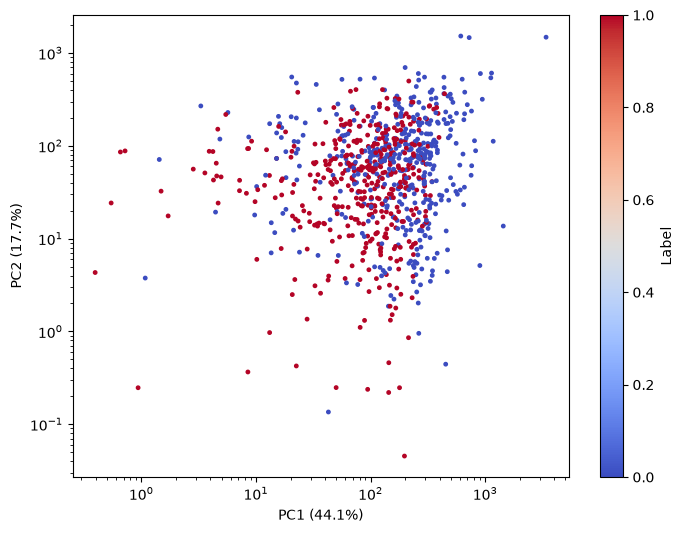

In [ ]:

fig, ax = plt.subplots(figsize=(8, 6))
scatter = ax.scatter(xy[:, 0], xy[:, 3], c=labels, cmap='coolwarm', s=6)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})") 
plt.colorbar(scatter, ax=ax, label='Label')
ax.set_yscale('log')
ax.set_xscale('log')

In [212]:
candidates_cropped_2 = candidates_cropped[0]

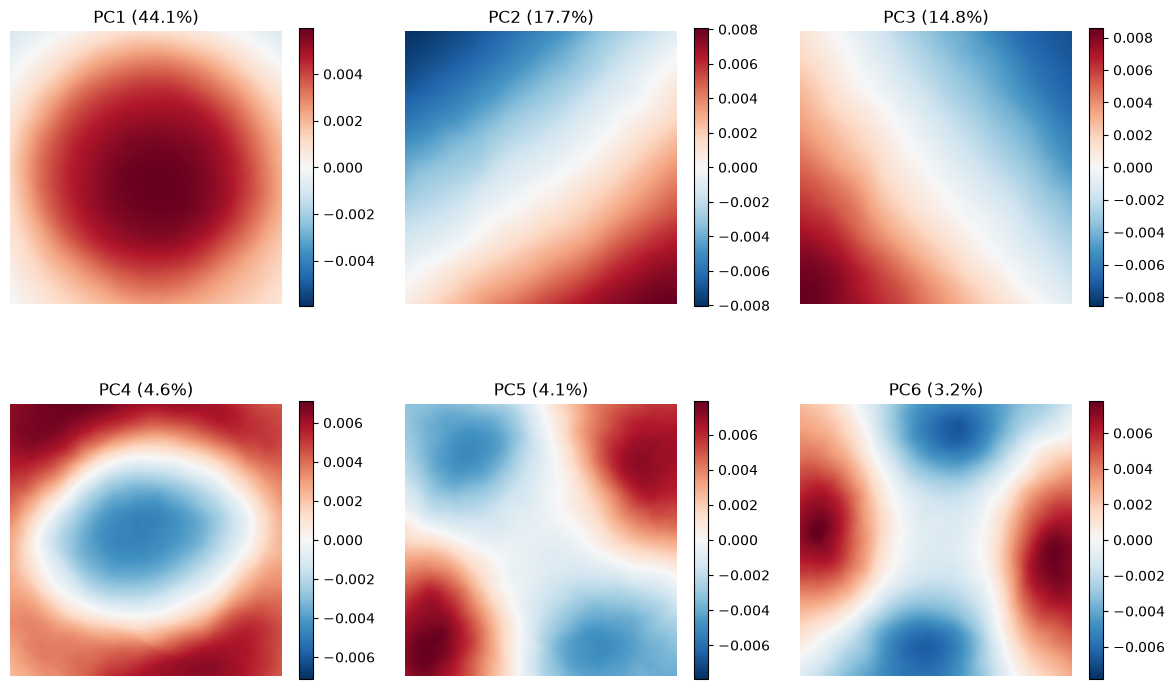

In [213]:
pca = PCA(n_components=6, svd_solver='randomized', random_state=0).fit(X)
h, w = candidates_cropped_2.shape

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for i, ax in enumerate(axes.flat):
    comp = pca.components_[i].reshape(h, w)
    lim = np.abs(comp).max()
    im = ax.imshow(comp, cmap='RdBu_r', vmin=-lim, vmax=lim)
    ax.set_title(f"PC{i+1} ({pca.explained_variance_ratio_[i]:.1%})")
    ax.axis('off')
    fig.colorbar(im, ax=ax, shrink=0.7)
plt.tight_layout()

# flatten